# Change in fastball velocity after return and subsequent arm injury in MLB pitchers (v5.1)

**Question.** Among MLB pitchers returning from an arm IL placement, is the change in fastball velocity
between before the injury and the first appearances back associated with a subsequent arm IL placement
the same season?

**Design** (following Brown & Do, 2022, *Research in Sports Medicine*: post- minus pre-injury differences,
logistic regression, group comparison of the differences), adapted for velocity:

* **Unit**: pitcher-season with an initial arm IL placement, first return by August 31, at least 5
  post-return appearances. Each season is its own unit (no carry-over).
* **Landmark**: exposure = his first `LANDMARK` (5) appearances back; outcome = a subsequent arm IL placement
  that season **after** that appearance. Exposure precedes the outcome and every exposure window has the same
  length.
* **Exposures**: post-return minus pre-injury mean fastball velocity, split into **mph lost** and **mph
  gained**; and the difference in average within-game CV.
* **Analysis**: Table 1 (characteristics), Table 2 (differences by outcome, Wilcoxon rank-sum), logistic
  regression with pitcher-clustered 95% CIs, predicted risk, sensitivity analyses.
* **Seasons (new in v5.1)**: 2016–2019 and 2021–2026 pooled (ten seasons). 2015 is left out (its baselines
  reach into 2014 PITCHf/x data); 2020 is left out (60-game season). 2016–2019 injury rows are rebuilt from
  MLB transactions (`MLB_Transactions_IL_2015_2019.ipynb`; 94% of FanGraphs' 2021–2023 pitcher rows
  reproduced).
* **Eras**: the IL minimum changed (15 days → 10 in 2017 → 15 for pitchers in 2022), which changes what
  reaches the IL, so the primary model adjusts for **IL era**. The pitch-tracking system changed (PITCHf/x →
  TrackMan in 2017 → Hawk-Eye in 2020); when a pre-injury window crosses a change, the velocity difference
  mixes systems, so Section 12 recomputes it within one system.

Outputs go to `data/arm_velocity_logistic_v51/`. Run top to bottom; all rules are in the Settings cell.

## 1. Settings

In [2]:
from pathlib import Path
import io
import re
import time
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

WORKSPACE = Path.cwd()
DATA_DIR = WORKSPACE / "data"
DATA_DIR.mkdir(exist_ok=True)
STATCAST_CACHE = DATA_DIR / "statcast"              # shared with the replication notebook
STATCAST_CACHE.mkdir(exist_ok=True)
CHADWICK_CACHE = DATA_DIR / "chadwick_register_ids.csv"
OUT_DIR = DATA_DIR / "arm_velocity_logistic_v51"
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)
INJURY_WORKBOOK = Path('/workspaces/Sports-Analytics-and-Intelligence-Lab/MLB Injuries/MLB Injuries Raw Data 2015-2026.xlsx')
if not INJURY_WORKBOOK.exists():
    raise FileNotFoundError(f"Expected workbook was not found: {INJURY_WORKBOOK}")

# ---- Seasons ----
SEASONS = [2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024, 2025, 2026]   # all pooled; no 2015, no 2020
TRAIN_SEASONS = SEASONS             # every season is analysed (name kept for the shared cohort code)

# ---- Cohort rules ----
PITCHER_POSITIONS = {"RP", "SP", "SP/RP", "RP/SP", "P"}
FIRST_RETURN_CUTOFF = "08-31"       # first return by August 31 (as in the WHIP paper)
MIN_POST_RETURN_APPS = 5            # at least 5 post-return appearances (as in the WHIP paper)
PATTERNS = {
    "elbow": re.compile(r"elbow|\bucl\b|ulnar|tommy john|flexor|pronator|forearm|epicondyl|olecranon|"
                        r"valgus|internal brace", flags=re.IGNORECASE),
    "arm":   re.compile(r"elbow|\bucl\b|ulnar|tommy john|flexor|pronator|forearm|epicondyl|olecranon|"
                        r"valgus|internal brace|shoulder|rotator|labrum|\bbicep|\btricep|\barm\b|\blat\b|"
                        r"latissimus|teres|thoracic outlet|capsul", flags=re.IGNORECASE),
}
INITIAL_GROUP = "arm"               # "arm" or "elbow": which initial IL placements define the cohort
SUBSEQUENT_GROUP = "arm"            # "arm" or "elbow": which later placement counts as a case
OUTCOME_LABEL = SUBSEQUENT_GROUP    # used in figure titles
COVID_PATTERN = re.compile(r"covid", flags=re.IGNORECASE)

# ---- Game-level statistics ----
FASTBALLS = ["FF", "SI"]            # primary fastball = whichever he threw more before the injury
LOOKBACK_DAYS = 365                 # baseline window before the initial arm injury
MIN_FB_GAME = 8                     # a game needs >= 8 primary fastballs to give a mean / SD / CV
FIRST_N_FB = 20                     # sensitivity analysis: CV from the first 20 primary fastballs
REST_CAP = 10                       # (kept from v3; not used by the charts)
SHRINK_BY_ROLE = True               # shrink each pitcher toward his role's mean (starter / reliever / mixed)
MIN_UNITS_ROLE_FIT = 10             # a role needs >= 10 training units for its own fit (else league-wide)

# ---- Pitch-tracking systems and IL-rule eras ----
TRACKING_SYSTEMS = [("PITCHf/x", "2008-01-01"), ("TrackMan", "2017-01-01"), ("Hawk-Eye", "2020-01-01")]
BASELINE_SAME_SYSTEM = False        # True: baselines use only games tracked by the monitored season's system
IL_ERAS = [("15-day DL (2015-16)", 2015), ("10-day DL/IL (2017-21)", 2017), ("15-day IL, pitchers (2022-)", 2022)]
STRATIFY_BY_ERA = True              # Mantel-Haenszel risk ratios stratified by role x IL era (else role only)


def tracking_system(dates):
    """System that tracked pitches on these dates (array-like of timestamps)."""
    d = pd.to_datetime(pd.Series(dates)).to_numpy()
    out = np.full(len(d), TRACKING_SYSTEMS[0][0], dtype=object)
    for name, start in TRACKING_SYSTEMS[1:]:
        out[d >= np.datetime64(start)] = name
    return out


def il_era(season):
    return [name for name, start in IL_ERAS if season >= start][-1]


# ---- Landmark logistic regression ----
LANDMARK = 5                        # exposure = first 5 appearances back; outcome = arm IL after the 5th
LANDMARK_SENS = 3                   # sensitivity analysis
MIN_BASE_GAMES = 3                  # pre-injury games with >= MIN_FB_GAME primary fastballs (for CV)
MIN_LANDMARK_GAMES = 2              # qualifying games among the first LANDMARK appearances (for CV)
CV_SCALE = 0.1                      # CV odds ratios are per 0.1 percentage points
SEED = 2026

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()


print("Seasons analysed:", SEASONS, "| landmark:", LANDMARK, "appearances")
print("Outputs:", OUT_DIR)

Seasons analysed: [2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024, 2025, 2026] | landmark: 5 appearances
Outputs: /workspaces/Sports-Analytics-and-Intelligence-Lab/MLB Pitcher Injuries/data/arm_velocity_logistic_v51


## 2. Injury records

Loads every season sheet, keeps pitcher rows with an IL date, and classifies each description as arm /
not arm and COVID / not COVID. Pitchers are keyed by **FanGraphs ID** rather than name, so accented
names cannot break the join (the issue behind the Table 2 baseline row). If a sheet has no
`key_fangraphs` column, the ID is read from the FanGraphs URL. Rows rebuilt from MLB transactions
(2015–2019) also carry `key_mlbam`, which is used directly for Statcast.

Rebuilt rows whose transaction gave **no injury text** cannot be classified; they count as non-arm (an
initial placement is missed; a later one stops a control). The table shows how many there are per season.

For the baseline window, the injury date is the **earlier** of the injury/surgery date and the IL date.
This matters for stints carried over from a previous season (e.g. Tommy John surgery the year before):
their IL date is opening day, but the pre-injury games are the ones before the surgery.

In [3]:
def clean_id(value):
    """IDs as plain strings: 12447.0 -> '12447', ' sa3012 ' -> 'sa3012'."""
    if pd.isna(value):
        return None
    text = str(value).strip()
    if not text:
        return None
    return text[:-2] if text.endswith(".0") else text


def fangraphs_id(row):
    value = clean_id(row.get("key_fangraphs"))
    if value:
        return value
    for column in ["URL", "sub_url"]:
        text = row.get(column)
        if isinstance(text, str):
            match = (re.search(r"/players/[^/]+/([^/?#]+)", text)
                     or re.match(r"[^/]+/([^/?#]+)/", text))
            if match:
                return match.group(1)
    return None


excel_file = pd.ExcelFile(INJURY_WORKBOOK)
tables = []
for sheet in excel_file.sheet_names:
    try:
        season = int(str(sheet).strip())
    except ValueError:
        continue
    if season in SEASONS:
        table = pd.read_excel(excel_file, sheet_name=sheet)
        table["Season"] = season
        tables.append(table)
missing_sheets = sorted(set(SEASONS) - {int(t["Season"].iloc[0]) for t in tables if len(t)})
if missing_sheets:
    raise ValueError(f"Workbook has no sheet for seasons {missing_sheets}")

injuries = pd.concat(tables, ignore_index=True).rename(columns={
    "IL Retro Date": "IL_Date", "Return Date": "Return_Date",
    "Injury / Surgery": "Injury", "Injury / Surgery Date": "Injury_Date"})
for column in ["IL_Date", "Return_Date", "Injury_Date"]:
    if column not in injuries.columns:
        injuries[column] = pd.NaT
    injuries[column] = pd.to_datetime(injuries[column], errors="coerce")

injuries["Pos"] = injuries["Pos"].astype(str).str.strip().str.upper()
injuries["Injury"] = injuries["Injury"].fillna("").astype(str).str.strip()
injuries["FanGraphs_ID"] = injuries.apply(fangraphs_id, axis=1)
injuries["MLBAM_ID"] = injuries["key_mlbam"].map(clean_id) if "key_mlbam" in injuries else None
injuries["pkey"] = injuries["FanGraphs_ID"].where(
    injuries["FanGraphs_ID"].notna(),
    ("mlbam:" + injuries["MLBAM_ID"].astype(str)).where(injuries["MLBAM_ID"].notna(), "name:" + injuries["Name"].astype(str)))
injuries = injuries.loc[injuries["Pos"].isin(PITCHER_POSITIONS) & injuries["IL_Date"].notna()].copy()
injuries = injuries.drop_duplicates(["pkey", "Season", "IL_Date", "Injury"])
injuries["is_covid"] = injuries["Injury"].str.contains(COVID_PATTERN)
non_throwing = injuries["Injury"].str.contains("non-throwing", case=False)
for group, pattern in PATTERNS.items():
    injuries[f"is_{group}"] = injuries["Injury"].str.contains(pattern) & ~non_throwing
injuries["is_initial"] = injuries[f"is_{INITIAL_GROUP}"]
injuries["is_subseq"] = injuries[f"is_{SUBSEQUENT_GROUP}"]
injuries["onset"] = injuries[["Injury_Date", "IL_Date"]].min(axis=1)
injuries = injuries.sort_values(["pkey", "Season", "IL_Date"], kind="stable").reset_index(drop=True)

display(injuries.groupby("Season").agg(pitcher_IL_rows=("pkey", "size"),
                                      initial_type_rows=("is_initial", "sum"),
                                      subsequent_type_rows=("is_subseq", "sum"),
                                      covid_rows=("is_covid", "sum"),
                                      blank_injury_text=("Injury", lambda s: int((s == "").sum())),
                                      missing_fangraphs_id=("FanGraphs_ID", lambda s: int(s.isna().sum()))))

# Every description and how it was classified, for a line-by-line check of the rule.
classification_review = (injuries.loc[~injuries["is_covid"]]
                         .groupby(["is_arm", "is_elbow", "Injury"]).size().rename("IL rows").reset_index()
                         .sort_values(["is_arm", "is_elbow", "IL rows"], ascending=[False, False, False]))
classification_review.to_csv(OUT_DIR / "injury_classification_review.csv", index=False)
print(f"Initial injury group: {INITIAL_GROUP} | subsequent injury group: {SUBSEQUENT_GROUP}")
print("Arm descriptions (is_elbow marks the elbow subset):")
with pd.option_context("display.max_rows", 300):
    display(classification_review.loc[classification_review["is_arm"]])
print("Most common non-arm descriptions (full list in injury_classification_review.csv):")
display(classification_review.loc[~classification_review["is_arm"]].head(30))

,pitcher_IL_rows,initial_type_rows,subsequent_type_rows,covid_rows,blank_injury_text,missing_fangraphs_id
Season,,,,,,
2016,302,174,174,0,3,2
2017,383,184,184,0,22,4
2018,432,219,219,0,9,2
2019,400,225,225,0,11,1
2021,687,303,303,130,0,0
2022,559,285,285,10,0,0
2023,502,293,293,2,0,0
2024,483,320,320,2,0,0
2025,458,292,292,0,0,0


Initial injury group: arm | subsequent injury group: arm
Arm descriptions (is_elbow marks the elbow subset):


,is_arm,is_elbow,Injury,IL rows
1127,True,True,Tommy John surgery,309
914,True,True,Elbow inflammation,158
1118,True,True,Strained forearm,76
1072,True,True,Right elbow inflammation,35
905,True,True,Elbow discomfort,34
...,...,...,...,...
880,True,False,Triceps discomfort,1
882,True,False,Triceps soreness,1
885,True,False,Vascular surgery (upper arm aneurysm),1
886,True,False,inflammation in left shoulder,1


Most common non-arm descriptions (full list in injury_classification_review.csv):


,is_arm,is_elbow,Injury,IL rows
562,False,False,Strained oblique,123
544,False,False,Strained hamstring,104
543,False,False,Strained groin,82
628,False,False,Undisclosed,63
557,False,False,Strained lower back,52
0,False,False,,45
535,False,False,Strained calf,38
191,False,False,Knee inflammation,33
267,False,False,Left oblique strain,31
508,False,False,Sprained ankle,24


## 3. Cohort: initial arm IL placement → subsequent arm IL placement

For each pitcher-season, the **initial** placement is his first arm placement of that season. The
**next** non-COVID placement after his return decides the outcome: arm → case (chart runs up to that IL
date); anything else → control, chart stops at that IL date; none → control, chart runs to the end of the
season.

In [4]:
initial_rows = injuries.loc[injuries["is_initial"] & ~injuries["is_covid"]]
units = (initial_rows.groupby(["pkey", "Season"], as_index=False, sort=False).head(1)
              [["pkey", "Name", "Season", "FanGraphs_ID", "MLBAM_ID", "Team", "Pos", "Injury", "Injury_Date",
                "IL_Date", "onset", "Return_Date"]]
              .rename(columns={"Injury": "initial_injury"})
              .reset_index(drop=True))
funnel = [("Pitcher-seasons with an arm IL placement", len(units))]

cutoff = pd.to_datetime(units["Season"].astype(str) + "-" + FIRST_RETURN_CUTOFF)
units = units.loc[units["Return_Date"].notna()]
funnel.append(("... with a return date", len(units)))
units = units.loc[units["Return_Date"] >= units["IL_Date"]]
funnel.append(("... return on or after the IL date", len(units)))
units = units.loc[units["Return_Date"] <= cutoff.loc[units.index]].copy()
funnel.append((f"... first return by {FIRST_RETURN_CUTOFF}", len(units)))

# Next non-COVID IL placement after the return, same season.
later = injuries.loc[~injuries["is_covid"], ["pkey", "Season", "IL_Date", "Injury", "is_subseq"]].merge(
    units[["pkey", "Season", "Return_Date"]], on=["pkey", "Season"])
later = later.loc[later["IL_Date"] > later["Return_Date"]].sort_values(["pkey", "Season", "IL_Date"])
next_il = later.groupby(["pkey", "Season"], as_index=False).head(1)
any_later_subseq = later.loc[later["is_subseq"]].groupby(["pkey", "Season"]).size().rename("n_later_subseq")

units = units.merge(next_il[["pkey", "Season", "IL_Date", "Injury", "is_subseq"]]
                    .rename(columns={"IL_Date": "next_il_date", "Injury": "next_injury",
                                     "is_subseq": "next_is_subseq"}),
                    on=["pkey", "Season"], how="left")
units = units.merge(any_later_subseq, left_on=["pkey", "Season"], right_index=True, how="left")
units["next_is_subseq"] = units["next_is_subseq"].astype("boolean").fillna(False).astype(bool)
units["case"] = units["next_is_subseq"].astype(int)
units["event_date"] = units["next_il_date"].where(units["case"] == 1)
units["censor_date"] = units["next_il_date"].where(units["case"] == 0)
units["stop_date"] = units["next_il_date"].fillna(pd.to_datetime(units["Season"].astype(str) + "-12-31")
                                                  + pd.Timedelta(days=1))
units["outcome"] = np.select(
    [units["case"] == 1, units["censor_date"].notna()],
    ["case: subsequent arm IL", "control: stopped at non-arm IL"],
    default="control: no later IL")

n_subseq_after_other = int(((units["case"] == 0) & units["n_later_subseq"].notna()).sum())
print("Controls whose next placement was non-arm but who had an arm placement later that season:",
      n_subseq_after_other, "(kept as controls, as specified)")
display(pd.crosstab(units["Season"], units["outcome"], margins=True))

Controls whose next placement was non-arm but who had an arm placement later that season: 9 (kept as controls, as specified)


outcome,case: subsequent arm IL,control: no later IL,control: stopped at non-arm IL,All
Season,,,,
2016,10,52,1,63
2017,21,56,12,89
2018,25,73,13,111
2019,24,70,17,111
2021,32,75,22,129
2022,28,64,19,111
2023,23,74,19,116
2024,33,78,15,126
2025,27,63,17,107


## 4. MLBAM IDs and Baseball Savant pitch data

Statcast uses MLBAM IDs, linked to FanGraphs IDs by the Chadwick register (cached by the replication
notebook; downloaded here if missing). Each pitcher's window runs from 365 days before the initial arm
injury to November 30 of the monitored season. Cached files from the replication notebook are used when
they cover the window; otherwise only the missing earlier dates are downloaded and cached as a separate
file.

In [5]:
CHADWICK_URL = "https://raw.githubusercontent.com/chadwickbureau/register/master/data/people-{}.csv"
if CHADWICK_CACHE.exists():
    id_map = pd.read_csv(CHADWICK_CACHE, dtype=str)
else:
    parts = []
    for suffix in "0123456789abcdef":
        part = pd.read_csv(CHADWICK_URL.format(suffix), usecols=["key_mlbam", "key_fangraphs"],
                           dtype=str, low_memory=False)
        parts.append(part.dropna())
        time.sleep(0.5)
    id_map = pd.concat(parts, ignore_index=True)
    id_map.to_csv(CHADWICK_CACHE, index=False)
fg_to_mlbam = dict(zip(id_map["key_fangraphs"].map(clean_id), id_map["key_mlbam"].map(clean_id)))

units["mlbam"] = units["MLBAM_ID"].where(units["MLBAM_ID"].notna(),
                                         units["FanGraphs_ID"].map(lambda v: fg_to_mlbam.get(v) if v else None))
no_id = units.loc[units["mlbam"].isna(), ["Name", "Season", "FanGraphs_ID"]]
if len(no_id):
    print("No MLBAM ID (dropped):")
    display(no_id)
units = units.loc[units["mlbam"].notna()].copy()
units["mlbam"] = units["mlbam"].astype(int)
funnel.append(("... with an MLBAM ID", len(units)))
units["window_start"] = (units["onset"] - pd.Timedelta(days=LOOKBACK_DAYS)).dt.normalize()
units["window_end"] = pd.to_datetime(units["Season"].astype(str) + "-11-30")
print("Pitcher-seasons to download:", len(units))

No MLBAM ID (dropped):


,Name,Season,FanGraphs_ID
832,Coleman Crow,2026,27926
836,Wilber Dotel,2026,28901
838,Kendry Rojas,2026,29423
861,Marco Raya,2026,30166
915,Tatsuya Imai,2026,37124
1082,Dylan File,2021,sa3004197
1083,Shane Drohan,2024,sa3014447
1084,Daniel Tillo,2021,sa876284


Pitcher-seasons to download: 1077


In [6]:
SAVANT_URL = (
    "https://baseballsavant.mlb.com/statcast_search/csv?all=true&type=details&player_type=pitcher"
    "&hfGT=R%7C&hfSea=&game_date_gt={start}&game_date_lt={end}&pitchers_lookup%5B%5D={mlbam}"
    "&min_pitches=0&min_results=0&min_abs=0&group_by=name&sort_col=pitches&sort_order=desc"
)
SAVANT_KEEP = ["pitcher", "game_pk", "game_date", "game_type", "inning", "at_bat_number",
               "pitch_number", "pitch_type", "release_speed", "p_throws"]
CACHE_NAME = re.compile(r"(\d+)_(\d{8})_(\d{8})\.csv")


def download_statcast(mlbam, start, end, sleep_seconds=2.0, retries=3):
    """One Savant request (regular season), saved in the shared cache with the same file naming."""
    path = STATCAST_CACHE / f"{mlbam}_{start:%Y%m%d}_{end:%Y%m%d}.csv"
    if path.exists():
        return pd.read_csv(path)
    url = SAVANT_URL.format(mlbam=mlbam, start=f"{start:%Y-%m-%d}", end=f"{end:%Y-%m-%d}")
    for attempt in range(1, retries + 1):
        try:
            time.sleep(sleep_seconds)
            request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urlopen(request, timeout=120) as response:
                text = response.read().decode("utf-8-sig")
            break
        except Exception as error:
            print(f"  attempt {attempt} failed for {mlbam}: {error!r}")
            time.sleep(10 * attempt)
    else:
        raise RuntimeError(f"Could not download Statcast data for pitcher {mlbam}")
    data = pd.read_csv(io.StringIO(text)) if text.strip() else pd.DataFrame(columns=SAVANT_KEEP)
    required = set(SAVANT_KEEP) - {"p_throws"}
    if len(data) and required - set(data.columns):
        raise ValueError(f"Unexpected Savant response for {mlbam}: {text[:300]!r}")
    if "game_type" in data.columns:
        data = data.loc[data["game_type"] == "R"]
    data = data[[c for c in SAVANT_KEEP if c in data.columns]]
    data.to_csv(path, index=False)
    return data


def cached_files(mlbam):
    out = []
    for path in STATCAST_CACHE.glob(f"{mlbam}_*.csv"):
        match = CACHE_NAME.fullmatch(path.name)
        if match and int(match.group(1)) == mlbam:
            out.append((pd.Timestamp(match.group(2)), pd.Timestamp(match.group(3)), path))
    return out


def statcast_window(mlbam, start, end):
    """Pitches for [start, end], from the cache where possible; downloads only the uncovered part."""
    files = cached_files(mlbam)
    pieces = [pd.read_csv(p) for s, e, p in files if s <= end and e >= start]   # overlapping files
    covered_from = min([s for s, e, p in files if s <= end and e >= end], default=None)
    if covered_from is None:                       # nothing reaches the end date: one full request
        pieces.append(download_statcast(mlbam, start, end))
    elif covered_from > start:                     # fetch only the earlier, uncovered dates
        pieces.append(download_statcast(mlbam, start, covered_from - pd.Timedelta(days=1)))
    pieces = [p for p in pieces if len(p)]
    if not pieces:
        return pd.DataFrame(columns=SAVANT_KEEP)
    data = pd.concat(pieces, ignore_index=True)
    data["game_date"] = pd.to_datetime(data["game_date"])
    return data.loc[data["game_date"].between(start, end)]


pieces, statcast_failures = [], []
for number, (_, row) in enumerate(units.drop_duplicates(["mlbam", "window_start", "window_end"]).iterrows(), 1):
    try:
        pieces.append(statcast_window(row["mlbam"], row["window_start"], row["window_end"]))
    except Exception as error:
        statcast_failures.append({"Name": row["Name"], "Season": row["Season"], "mlbam": row["mlbam"],
                                  "error": repr(error)})
    if number % 50 == 0:
        print(f"{number} windows ({len(statcast_failures)} failures)")
statcast_failures = pd.DataFrame(statcast_failures)
statcast_failures.to_csv(OUT_DIR / "statcast_fetch_failures.csv", index=False)
if len(statcast_failures):
    display(statcast_failures)

pitches = pd.concat(pieces, ignore_index=True)
if "p_throws" not in pitches.columns:
    pitches["p_throws"] = np.nan
pitches = pitches.dropna(subset=["game_pk", "at_bat_number", "pitch_number"]).copy()
pitches["pitcher"] = pitches["pitcher"].astype(int)
pitches["game_pk"] = pitches["game_pk"].astype(int)
pitches["game_date"] = pd.to_datetime(pitches["game_date"])
pitches = (pitches.drop_duplicates(["pitcher", "game_pk", "at_bat_number", "pitch_number"])
                  .sort_values(["pitcher", "game_date", "game_pk", "at_bat_number", "pitch_number"])
                  .reset_index(drop=True))
pitches["pitch_count"] = pitches.groupby(["pitcher", "game_pk"]).cumcount() + 1
pitches_by_pitcher = {p: g for p, g in pitches.groupby("pitcher")}
print(f"Pitches: {len(pitches):,} | pitchers: {pitches['pitcher'].nunique()}")

50 windows (1 failures)
100 windows (2 failures)
150 windows (2 failures)
200 windows (3 failures)
250 windows (5 failures)
300 windows (6 failures)
350 windows (9 failures)
400 windows (11 failures)
450 windows (17 failures)
500 windows (20 failures)
550 windows (23 failures)
600 windows (29 failures)
650 windows (34 failures)
700 windows (41 failures)
750 windows (53 failures)
800 windows (61 failures)
850 windows (66 failures)
900 windows (69 failures)
950 windows (70 failures)
1000 windows (70 failures)
1050 windows (74 failures)


,Name,Season,mlbam,error
0,Mike Minor,2022,501985,"NotImplementedError(""strftime not yet supporte..."
1,Tommy Kahnle,2023,592454,"NotImplementedError(""strftime not yet supporte..."
2,Dylan Floro,2022,571670,"NotImplementedError(""strftime not yet supporte..."
3,Lucas Sims,2022,608371,"NotImplementedError(""strftime not yet supporte..."
4,Josh Hader,2026,623352,"NotImplementedError(""strftime not yet supporte..."
...,...,...,...,...
70,Jay Jackson,2022,543351,"NotImplementedError(""strftime not yet supporte..."
71,Justin Verlander,2024,434378,"NotImplementedError(""strftime not yet supporte..."
72,Wade Miley,2022,489119,"NotImplementedError(""strftime not yet supporte..."
73,Wade Miley,2024,489119,"NotImplementedError(""strftime not yet supporte..."


Pitches: 1,653,886 | pitchers: 697


In [7]:
# Arm descriptions that name a side: flag any that do not match the throwing arm, for manual review.
throws = pitches.dropna(subset=["p_throws"]).groupby("pitcher")["p_throws"].agg(lambda s: s.mode().iat[0])
units["throws"] = units["mlbam"].map(throws)
side = units["initial_injury"].str.extract(r"\b(left|right)\b", flags=re.IGNORECASE, expand=False).str.upper().str[0]
side_check = units.assign(side=side).loc[lambda d: d["side"].notna()]
mismatch = side_check.loc[side_check["throws"].notna() & (side_check["side"] != side_check["throws"])]
print(f"Initial arm descriptions naming a side: {len(side_check)}; "
      f"side differs from the throwing arm: {len(mismatch)}")
if len(mismatch):
    display(mismatch[["Name", "Season", "initial_injury", "throws"]])

Initial arm descriptions naming a side: 348; side differs from the throwing arm: 13


,Name,Season,initial_injury,throws
227,Jon Moscot,2016,inflammation in left shoulder,R
250,Wandy Peralta,2019,Right hip flexor strain,L
257,Yohander Méndez,2019,Right UCL sprain,L
394,Harrison Musgrave,2018,Right hip flexor strain,L
422,Raisel Iglesias,2018,Left biceps strain,R
425,Domingo Germán,2019,Left hip flexor strain,R
839,Josh Ravin,2016,Left forearm fracture,R
881,Will Harris,2017,Left shoulder inflammation,R
941,Brandon McCarthy,2017,Left shoulder soreness,R
985,Steve Cishek,2016,Left hip labrum tear,R


## 5. Game-level fastball statistics

For each unit:

* **Primary fastball**: FF or SI, whichever he threw more in the 365 days before the injury (if he has no
  pre-injury fastballs, the post-return games decide).
* **Baseline games**: games in that pre-injury window with at least `MIN_FB_GAME` primary fastballs.
* **Monitored games**: games from the return date up to (not including) the stop date, with at least
  `MIN_FB_GAME` primary fastballs. Appearances with fewer fastballs leave the chart unchanged.
* **Post-return appearances** (for the 5-appearance rule) count every regular-season game after the return
  that season, as in the WHIP paper.
* **Tracking system**: each unit is flagged if any baseline game was tracked by a different system than his
  monitored games (PITCHf/x → TrackMan in 2017; TrackMan → Hawk-Eye in 2020). Section 13 reruns the
  comparison with baselines restricted to the same system.
* **Per-game statistics**: mean, SD and CV (= 100 × SD / mean) of primary-fastball velocity, and for the
  sensitivity analyses the CV of the first `FIRST_N_FB` fastballs and the CV of residuals around the game's
  own linear fade. Types are forced to numeric, which avoids the object-dtype `log` error.

In [8]:
def per_game(game_pitches, primary):
    """One row per game for the primary fastball: count, mean, SD, CV, plus two CV variants for the
    sensitivity analyses (first FIRST_N_FB fastballs; residuals around the game's own linear fade),
    and the logs of the three CVs. Games with fewer than MIN_FB_GAME primary fastballs are dropped."""
    cols = ["game_pk", "game_date", "n_fb", "velo", "sd", "cv", "cv_f20", "cv_resid", "n_pitches",
            "logcv", "logcv_f20", "logcv_resid"]
    fb = game_pitches.loc[game_pitches["pitch_type"] == primary,
                          ["game_pk", "game_date", "pitch_count", "release_speed"]].copy()
    fb["release_speed"] = pd.to_numeric(fb["release_speed"], errors="coerce").astype(float)
    fb["pitch_count"] = pd.to_numeric(fb["pitch_count"], errors="coerce").astype(float)
    fb = fb.dropna(subset=["release_speed", "pitch_count"])
    if fb.empty:
        return pd.DataFrame({c: pd.Series(dtype=float) for c in cols})
    grp = fb.groupby("game_pk")
    g = grp.agg(game_date=("game_date", "first"), n_fb=("release_speed", "size"),
                velo=("release_speed", "mean"), sd=("release_speed", "std")).reset_index()
    f20 = fb.groupby("game_pk", sort=False).head(FIRST_N_FB).groupby("game_pk")["release_speed"].agg(["mean", "std"])
    g["cv_f20"] = g["game_pk"].map(100 * f20["std"] / f20["mean"])
    xd = fb["pitch_count"] - grp["pitch_count"].transform("mean")
    yd = fb["release_speed"] - grp["release_speed"].transform("mean")
    slope = ((xd * yd).groupby(fb["game_pk"]).sum() / (xd ** 2).groupby(fb["game_pk"]).sum().replace(0, np.nan)).fillna(0)
    resid = yd - fb["game_pk"].map(slope) * xd
    sd_resid = np.sqrt((resid ** 2).groupby(fb["game_pk"]).sum() / (grp.size() - 2).clip(lower=1))
    g["cv"] = 100 * g["sd"] / g["velo"]
    g["cv_resid"] = 100 * g["game_pk"].map(sd_resid) / g["velo"]
    g["n_pitches"] = g["game_pk"].map(game_pitches.groupby("game_pk").size())
    g = g.loc[g["n_fb"] >= MIN_FB_GAME].sort_values(["game_date", "game_pk"]).reset_index(drop=True)
    for c in ["n_fb", "velo", "sd", "cv", "cv_f20", "cv_resid", "n_pitches"]:
        g[c] = pd.to_numeric(g[c], errors="coerce").astype(float)
    for c in ["cv", "cv_f20", "cv_resid"]:
        g["log" + c] = np.log(np.clip(g[c].to_numpy(float), 1e-6, None))
    return g[cols]


unit_data, drop_reason = {}, {}
units = units.reset_index(drop=True)
units["uid"] = units.index
for _, row in units.iterrows():
    g = pitches_by_pitcher.get(row["mlbam"])
    if g is None:
        drop_reason[row["uid"]] = "no Statcast pitches"
        continue
    season_end = pd.Timestamp(f"{int(row['Season'])}-12-31")
    pre = g.loc[(g["game_date"] >= row["window_start"]) & (g["game_date"] < row["onset"])]
    post = g.loc[(g["game_date"] >= row["Return_Date"]) & (g["game_date"] <= season_end)]
    monitored_raw = post.loc[post["game_date"] < row["stop_date"]]

    fb_counts = pre.loc[pre["pitch_type"].isin(FASTBALLS), "pitch_type"].value_counts()
    if fb_counts.empty:
        fb_counts = monitored_raw.loc[monitored_raw["pitch_type"].isin(FASTBALLS), "pitch_type"].value_counts()
    if fb_counts.empty:
        drop_reason[row["uid"]] = "no four-seam or sinker"
        continue
    primary = fb_counts.idxmax()

    apps = post.drop_duplicates("game_pk")[["game_pk", "game_date"]].sort_values(["game_date", "game_pk"])
    if len(apps) < MIN_POST_RETURN_APPS:
        drop_reason[row["uid"]] = f"fewer than {MIN_POST_RETURN_APPS} post-return appearances"
        continue
    apps_before_stop = apps.loc[apps["game_date"] < row["stop_date"]].reset_index(drop=True)
    monitored = per_game(monitored_raw, primary)
    if monitored.empty:
        drop_reason[row["uid"]] = "no monitored game with enough fastballs"
        continue
    pre_games = pre.groupby("game_pk")["inning"].min()
    ref_games = pre_games if len(pre_games) else monitored_raw.groupby("game_pk")["inning"].min()
    start_share = (ref_games == 1).mean() if len(ref_games) else np.nan
    role = ("unknown" if np.isnan(start_share) else "starter" if start_share >= 0.6
            else "reliever" if start_share <= 0.2 else "mixed")
    app_index = {pk: i for i, pk in enumerate(apps_before_stop["game_pk"])}
    monitored["app_index"] = monitored["game_pk"].map(app_index)      # 0 = first appearance back
    rest = apps_before_stop["game_date"].diff().dt.days.fillna(REST_CAP)   # first game back = long rest
    monitored["rest_days"] = monitored["game_pk"].map(dict(zip(apps_before_stop["game_pk"], rest)))
    base_games = per_game(pre, primary)
    season_system = tracking_system([row["Return_Date"]])[0]
    unit_data[row["uid"]] = {
        "season_system": season_system,
        "baseline_crosses_system": bool(len(base_games) and (tracking_system(base_games["game_date"]) != season_system).any()),
        "primary": primary,
        "role": role,
        "baseline": base_games,
        "monitored": monitored,
        "n_apps_before_stop": len(apps_before_stop),
        "n_post_return_apps": len(apps),
    }

units["dropped"] = units["uid"].map(drop_reason)
for reason, n in units["dropped"].value_counts().items():
    print(f"Dropped: {reason}: {n}")
units = units.loc[units["dropped"].isna()].drop(columns="dropped")   # index stays = uid
funnel.append((f"... with Statcast data, >= {MIN_POST_RETURN_APPS} post-return appearances, "
               "and >= 1 monitored game", len(units)))
units["split"] = "analysed"
units["primary"] = units["uid"].map(lambda u: unit_data[u]["primary"])
units["role"] = units["uid"].map(lambda u: unit_data[u]["role"])
units["baseline_games"] = units["uid"].map(lambda u: len(unit_data[u]["baseline"]))
units["monitored_games"] = units["uid"].map(lambda u: len(unit_data[u]["monitored"]))
units["era"] = units["Season"].map(il_era)
units["tracking_system"] = units["uid"].map(lambda u: unit_data[u]["season_system"])
units["baseline_crosses_system"] = units["uid"].map(lambda u: unit_data[u]["baseline_crosses_system"])

funnel = pd.DataFrame(funnel, columns=["step", "pitcher-seasons"])
funnel.to_csv(OUT_DIR / "cohort_funnel.csv", index=False)
display(funnel)
cohort_table = (units.groupby(["split", "Season"])
                     .agg(units=("uid", "size"), cases=("case", "sum"),
                          controls_stopped_at_other_IL=("censor_date", lambda s: int(s.notna().sum())),
                          median_baseline_games=("baseline_games", "median"),
                          no_baseline_games=("baseline_games", lambda s: int((s == 0).sum())),
                          median_monitored_games=("monitored_games", "median")))
display(cohort_table)
display(pd.crosstab([units["split"], units["role"]], units["case"].map({1: "case", 0: "control"})))
print("Reinjury rate by IL era (the IL minimum changes what reaches the IL):")
display(units.groupby(["split", "era"]).agg(units=("uid", "size"), cases=("case", "sum"),
                                           reinjury_rate=("case", "mean")).round(3))
print("Units whose baseline includes games from a different tracking system than their season:")
display(units.groupby(["split", "Season"])["baseline_crosses_system"].agg(["sum", "size"])
        .rename(columns={"sum": "baseline crosses system", "size": "units"}))
units.drop(columns=["window_start", "window_end"]).to_csv(OUT_DIR / "cohort_units.csv", index=False)

Dropped: fewer than 5 post-return appearances: 203
Dropped: no Statcast pitches: 49
Dropped: no monitored game with enough fastballs: 37
Dropped: no four-seam or sinker: 24


,step,pitcher-seasons
0,Pitcher-seasons with an arm IL placement,2307
1,... with a return date,1749
2,... return on or after the IL date,1748
3,... first return by 08-31,1085
4,... with an MLBAM ID,1077
5,"... with Statcast data, >= 5 post-return appea...",764


units  cases  controls_stopped_at_other_IL  \
split    Season                                               
analysed 2016       49      7                             1   
         2017       68     16                             8   
         2018       80     14                            11   
         2019       79     16                            13   
         2021       88     20                            16   
         2022       78     19                            15   
         2023       77     15                            14   
         2024       82     21                            10   
         2025       79     22                            11   
         2026       84     12                            13   

                 median_baseline_games  no_baseline_games  \
split    Season                                             
analysed 2016                     23.0                  1   
         2017                     26.0                  1   
         2018                     21.5                  5   
         2019                     24.0                  4   
         2021                     14.0                  3   
         2022                     19.0                  1   
         2023                     19.0                  5   
         2024                     20.5                  4   
         2025                     19.0                  5   
         2026                     19.0                  2   

                 median_monitored_games  
split    Season                          
analysed 2016                       9.0  
         2017                       9.0  
         2018                       7.0  
         2019                      10.0  
         2021                       7.5  
         2022                       8.0  
         2023                       8.0  
         2024                       8.0  
         2025                       8.0  
         2026                       9.0

case               case  control
split    role                   
analysed mixed       12       27
         reliever    83      321
         starter     67      254

Reinjury rate by IL era (the IL minimum changes what reaches the IL):


units  cases  reinjury_rate
split    era                                                     
analysed 10-day DL/IL (2017-21)         315     66          0.210
         15-day DL (2015-16)             49      7          0.143
         15-day IL, pitchers (2022-)    400     89          0.222

Units whose baseline includes games from a different tracking system than their season:


baseline crosses system  units
split    Season                                
analysed 2016                          0     49
         2017                         64     68
         2018                          2     80
         2019                          1     79
         2021                          4     88
         2022                          2     78
         2023                          0     77
         2024                          0     82
         2025                          0     79
         2026                          0     84

## 6. Age at return (Chadwick register birth dates)

Age is taken from the Chadwick register's birth dates (cached in `data/`). If the download fails, age is
left out of the models and the cell says so.

In [9]:
BIRTH_CACHE = DATA_DIR / "chadwick_register_birth.csv"
if not BIRTH_CACHE.exists():
    try:
        parts = []
        for suffix in "0123456789abcdef":
            part = pd.read_csv(CHADWICK_URL.format(suffix),
                               usecols=["key_mlbam", "birth_year", "birth_month", "birth_day"],
                               dtype=str, low_memory=False)
            parts.append(part.dropna(subset=["key_mlbam", "birth_year"]))
            time.sleep(0.5)
        pd.concat(parts, ignore_index=True).to_csv(BIRTH_CACHE, index=False)
    except Exception as error:
        print("Could not download birth dates:", repr(error))
if BIRTH_CACHE.exists():
    births = pd.read_csv(BIRTH_CACHE, dtype=str)
    births["key_mlbam"] = births["key_mlbam"].map(clean_id)
    births = births.dropna(subset=["key_mlbam"]).drop_duplicates("key_mlbam").set_index("key_mlbam")
    birth_date = pd.to_datetime(dict(year=pd.to_numeric(births["birth_year"], errors="coerce"),
                                     month=pd.to_numeric(births["birth_month"], errors="coerce").fillna(7),
                                     day=pd.to_numeric(births["birth_day"], errors="coerce").fillna(1)),
                                errors="coerce")
    units["birth_date"] = units["mlbam"].astype(str).map(birth_date)
else:
    units["birth_date"] = pd.NaT
units["age"] = (units["Return_Date"] - units["birth_date"]).dt.days / 365.25
USE_AGE = units["age"].notna().mean() >= 0.9
print(f"Age available for {units['age'].notna().mean():.0%} of units; age in the models: {USE_AGE}")

Age available for 100% of units; age in the models: True


## 7. Landmark exposures: velocity and CV before the injury vs the first appearances back

For each pitcher-season:

* **Pre-injury**: all primary fastballs in the 365 days before the initial arm injury (mean velocity), and
  the average **within-game CV** over those games with at least `MIN_FB_GAME` primary fastballs (needs at
  least `MIN_BASE_GAMES` such games).
* **Post-return**: the same two quantities over his **first `LANDMARK` appearances back** (CV needs at least
  `MIN_LANDMARK_GAMES` qualifying games among them).
* **Difference** = post-return minus pre-injury, as in the 2022 paper. Velocity is split into **mph lost**
  (the drop below his pre-injury mean, 0 if he is at or above it) and **mph gained** (the rise above it, 0 if
  at or below), so each direction gets its own odds ratio.
* **Outcome**: a subsequent arm IL placement that season **after** his `LANDMARK`-th appearance back. Exposure
  therefore strictly precedes the outcome, and everyone's exposure window is the same length.

Pitcher-seasons whose follow-up ends before the landmark are not in the model: those reinjured (arm) within
the first `LANDMARK` appearances are counted and described separately; those whose next IL was non-arm before
the landmark are counted.

CV here is the average of **within-game** CVs. Pooling all fastballs across games into one CV would mix in
game-to-game shifts in velocity, which the velocity difference already captures.

In [10]:
def landmark_frame(L=LANDMARK, min_base=MIN_BASE_GAMES, min_land=MIN_LANDMARK_GAMES, outcome_group=None,
                   same_system=False):
    """One row per pitcher-season: status (included or why not), exposures, covariates, outcome.
    same_system: pre-injury games only from the tracking system of his monitored season."""
    rows = []
    for u in units["uid"]:
        row, d = units.loc[u], unit_data[u]
        g = pitches_by_pitcher[row["mlbam"]]
        speed_ok = pd.to_numeric(g["release_speed"], errors="coerce")
        prim = (g["pitch_type"] == d["primary"]) & speed_ok.notna()
        season_end = pd.Timestamp(f"{int(row['Season'])}-12-31")
        post = g.loc[(g["game_date"] >= row["Return_Date"]) & (g["game_date"] <= season_end)
                     & (g["game_date"] < row["stop_date"])]
        apps = post.drop_duplicates("game_pk").sort_values(["game_date", "game_pk"])
        first = apps["game_pk"].iloc[:L].tolist()
        land_games = d["monitored"].loc[d["monitored"]["game_pk"].isin(first)]
        base = d["baseline"]
        if same_system:
            base = base.loc[tracking_system(base["game_date"]) == d["season_system"]]
        if len(apps) < L:
            status = ("subsequent arm IL before landmark" if row["case"] == 1 else
                      "non-arm IL before landmark" if pd.notna(row["censor_date"]) else "fewer appearances than landmark")
        elif len(base) < min_base:
            status = "too few pre-injury games"
        elif len(land_games) < min_land:
            status = "too few qualifying games in landmark window"
        else:
            status = "included"
        pre_mask = prim & (g["game_date"] >= row["window_start"]) & (g["game_date"] < row["onset"])
        if same_system:
            pre_mask &= pd.Series(tracking_system(g["game_date"]) == d["season_system"], index=g.index)
        post_mask = prim & g["game_pk"].isin(first) & (g["game_date"] >= row["Return_Date"])
        case = int(row["case"])
        if outcome_group == "elbow":
            case = int(case == 1 and bool(PATTERNS["elbow"].search(str(row["next_injury"]))))
        rows.append({
            "uid": u, "pkey": row["pkey"], "Name": row["Name"], "Season": int(row["Season"]), "status": status,
            "case": case, "role": d["role"], "starter": float(d["role"] == "starter"), "age": row["age"],
            "elbow_initial": float(bool(PATTERNS["elbow"].search(str(row["initial_injury"])))),
            "il_days": max((row["Return_Date"] - row["IL_Date"]).days, 1),
            "pre_velo": speed_ok[pre_mask].mean(), "post_velo": speed_ok[post_mask].mean(),
            "pre_cv": base["cv"].mean(), "post_cv": land_games["cv"].mean(),
            "n_pre_games": len(base), "n_landmark_games": len(land_games),
            "era": row["era"], "baseline_crosses_system": d["baseline_crosses_system"],
            "days_return_to_landmark": (apps["game_date"].iloc[L - 1] - row["Return_Date"]).days if len(apps) >= L else np.nan,
            "days_landmark_to_IL": ((row["event_date"] - apps["game_date"].iloc[L - 1]).days
                                    if len(apps) >= L and row["case"] == 1 else np.nan)})
    f = pd.DataFrame(rows)
    f["d_velo"] = f["post_velo"] - f["pre_velo"]
    f["mph_lost"] = np.clip(-f["d_velo"], 0, None)
    f["mph_gained"] = np.clip(f["d_velo"], 0, None)
    f["d_cv"] = f["post_cv"] - f["pre_cv"]
    f["d_cv_scaled"] = f["d_cv"] / CV_SCALE
    f["log_il_days"] = np.log(f["il_days"])
    for name, _ in IL_ERAS[1:]:                       # era indicators, reference = the earliest era present
        f["era: " + name] = (f["era"] == name).astype(float)
    return f


LM = landmark_frame()
flow = (LM.groupby("status").agg(pitcher_seasons=("uid", "size"), arm_reinjuries=("case", "sum"))
          .sort_values("pitcher_seasons", ascending=False))
flow.loc["total"] = flow.sum()
flow.to_csv(OUT_DIR / "landmark_flow.csv")
display(flow)
D = LM.loc[LM["status"] == "included"].dropna(subset=["d_velo", "d_cv"]).reset_index(drop=True)
print(f"Analysed: {len(D)} pitcher-seasons, {int(D['case'].sum())} subsequent arm IL placements after the "
      f"landmark ({D['case'].mean():.1%}), {D['pkey'].nunique()} pitchers.")
early = LM.loc[LM["status"] == "subsequent arm IL before landmark"]
print(f"Reinjured (arm) within the first {LANDMARK} appearances, not in the model: {len(early)} "
      f"(they are {len(early) / max(len(early) + D['case'].sum(), 1):.0%} of all subsequent arm IL placements).")
D.to_csv(OUT_DIR / "landmark_analysis_data.csv", index=False)
print("By IL era (the IL minimum changes what reaches the IL):")
display(D.groupby("era").agg(pitcher_seasons=("uid", "size"), reinjuries=("case", "sum"), rate=("case", "mean"),
                             mean_velocity_change=("d_velo", "mean"),
                             baseline_crosses_tracking_system=("baseline_crosses_system", "sum")).round(3))

,pitcher_seasons,arm_reinjuries
status,,
included,536,102
too few qualifying games in landmark window,127,22
too few pre-injury games,50,9
subsequent arm IL before landmark,29,29
non-arm IL before landmark,22,0
total,764,162


Analysed: 536 pitcher-seasons, 102 subsequent arm IL placements after the landmark (19.0%), 412 pitchers.
Reinjured (arm) within the first 5 appearances, not in the model: 29 (they are 22% of all subsequent arm IL placements).
By IL era (the IL minimum changes what reaches the IL):


,pitcher_seasons,reinjuries,rate,mean_velocity_change,baseline_crosses_tracking_system
era,,,,,
10-day DL/IL (2017-21),227,42,0.185,-0.261,59
15-day DL (2015-16),34,5,0.147,-0.180,0
"15-day IL, pitchers (2022-)",275,55,0.200,-0.193,1


## 8. Table 1: characteristics of the analysed pitcher-seasons, by outcome

In [11]:
def fmt_mean(x, d=2):
    x = pd.Series(x).dropna()
    return f"{x.mean():.{d}f} ({x.std():.{d}f})" if len(x) else ""


def fmt_median(x, d=0):
    x = pd.Series(x).dropna()
    return f"{x.median():.{d}f} [{x.quantile(.25):.{d}f}–{x.quantile(.75):.{d}f}]" if len(x) else ""


def table1(df):
    out = {}
    for label, g in [("Subsequent arm IL", df.loc[df["case"] == 1]), ("No subsequent arm IL", df.loc[df["case"] == 0]),
                     ("All", df)]:
        out[label] = {
            "Pitcher-seasons, n": f"{len(g)}",
            "Starters, n (%)": f"{int(g['starter'].sum())} ({g['starter'].mean():.0%})",
            **{f"IL era {e}, n (%)": f"{int((g['era'] == e).sum())} ({(g['era'] == e).mean():.0%})"
               for e, _ in IL_ERAS if (df["era"] == e).any()},
            "Age at return, years, mean (SD)": fmt_mean(g["age"], 1),
            "Initial injury elbow/forearm, n (%)": f"{int(g['elbow_initial'].sum())} ({g['elbow_initial'].mean():.0%})",
            "Days on the IL, median [IQR]": fmt_median(g["il_days"]),
            "Pre-injury games, median [IQR]": fmt_median(g["n_pre_games"]),
            "Pre-injury fastball velocity, mph, mean (SD)": fmt_mean(g["pre_velo"]),
            "Post-return fastball velocity, mph, mean (SD)": fmt_mean(g["post_velo"]),
            "Pre-injury within-game CV, %, mean (SD)": fmt_mean(g["pre_cv"], 3),
            "Post-return within-game CV, %, mean (SD)": fmt_mean(g["post_cv"], 3),
            f"Days from return to appearance {LANDMARK}, median [IQR]": fmt_median(g["days_return_to_landmark"]),
        }
    return pd.DataFrame(out)


T1 = table1(D)
T1.to_csv(OUT_DIR / "table1_characteristics.csv")
display(T1)

,Subsequent arm IL,No subsequent arm IL,All
"Pitcher-seasons, n",102,434,536
"Starters, n (%)",50 (49%),221 (51%),271 (51%)
"IL era 15-day DL (2015-16), n (%)",5 (5%),29 (7%),34 (6%)
"IL era 10-day DL/IL (2017-21), n (%)",42 (41%),185 (43%),227 (42%)
"IL era 15-day IL, pitchers (2022-), n (%)",55 (54%),220 (51%),275 (51%)
"Age at return, years, mean (SD)",28.8 (3.4),29.4 (3.3),29.3 (3.3)
"Initial injury elbow/forearm, n (%)",51 (50%),188 (43%),239 (45%)
"Days on the IL, median [IQR]",34 [19–62],36 [20–63],36 [20–63]
"Pre-injury games, median [IQR]",20 [14–30],24 [14–30],23 [14–30]
"Pre-injury fastball velocity, mph, mean (SD)",94.18 (2.59),93.92 (2.35),93.97 (2.40)


## 9. Table 2: post-return minus pre-injury differences, by outcome

Mean (SD) and median of each difference for reinjured and non-reinjured pitcher-seasons, with the
**Wilcoxon rank-sum (Mann-Whitney) test**, the appropriate test for comparing two independent groups
(normal approximation with tie correction).

,Difference (post-return minus pre-injury),Subsequent arm IL: mean (SD),median,No subsequent arm IL: mean (SD),median,Wilcoxon rank-sum p
0,"Fastball velocity difference, mph",-0.261 (1.083),-0.285,-0.211 (0.911),-0.201,0.5944
1,mph lost,0.572 (0.700),0.285,0.480 (0.584),0.201,0.3968
2,mph gained,0.311 (0.569),0.000,0.268 (0.482),0.000,0.9307
3,"Within-game CV difference, % points",0.022 (0.186),-0.000,-0.017 (0.191),-0.021,0.0792


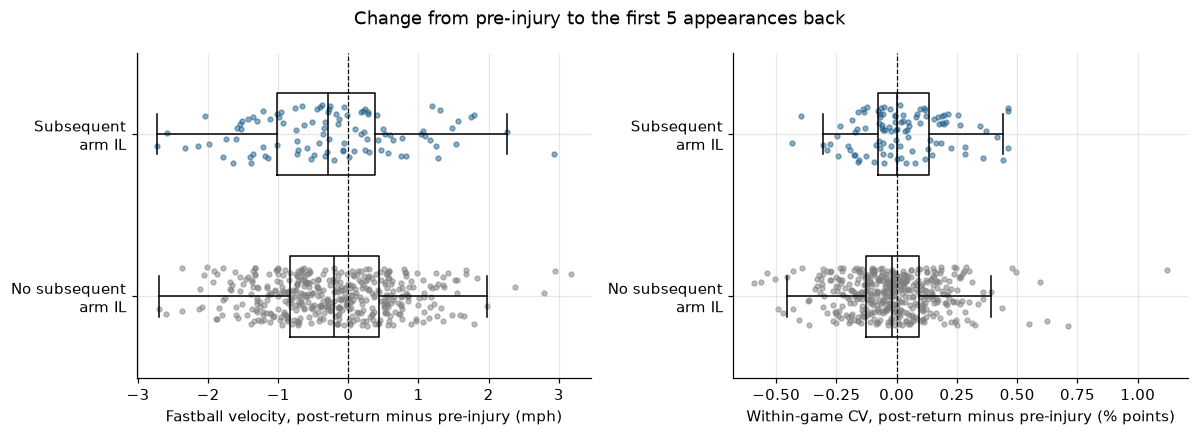

In [12]:
from math import erf, sqrt


def Phi(x):
    return 0.5 * (1 + erf(x / sqrt(2)))


def ranksum_test(x, y):
    """Two-sided Wilcoxon rank-sum (Mann-Whitney U) test, normal approximation with tie and continuity correction."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    x, y = x[~np.isnan(x)], y[~np.isnan(y)]
    n1, n2 = len(x), len(y)
    if n1 == 0 or n2 == 0:
        return np.nan, np.nan
    allv = np.r_[x, y]
    ranks = pd.Series(allv).rank().to_numpy()
    U = ranks[:n1].sum() - n1 * (n1 + 1) / 2
    n = n1 + n2
    _, t = np.unique(allv, return_counts=True)
    sigma = np.sqrt(n1 * n2 / 12 * ((n + 1) - (t ** 3 - t).sum() / (n * (n - 1))))
    z = (U - n1 * n2 / 2 - np.sign(U - n1 * n2 / 2) * 0.5) / sigma if sigma > 0 else 0.0
    return U, 2 * (1 - Phi(abs(z)))


# check against a hand-computed case: x = [1, 2], y = [3, 4] -> U = 0
assert ranksum_test([1, 2], [3, 4])[0] == 0


def table2(df):
    rows = []
    for var, label in [("d_velo", "Fastball velocity difference, mph"), ("mph_lost", "  mph lost"),
                       ("mph_gained", "  mph gained"), ("d_cv", "Within-game CV difference, % points")]:
        a, b = df.loc[df["case"] == 1, var], df.loc[df["case"] == 0, var]
        U, p = ranksum_test(a, b)
        rows.append({"Difference (post-return minus pre-injury)": label,
                     "Subsequent arm IL: mean (SD)": fmt_mean(a, 3), "median": f"{a.median():.3f}",
                     "No subsequent arm IL: mean (SD)": fmt_mean(b, 3), "median ": f"{b.median():.3f}",
                     "Wilcoxon rank-sum p": round(p, 4)})
    return pd.DataFrame(rows)


T2 = table2(D)
T2.to_csv(OUT_DIR / "table2_differences.csv", index=False)
display(T2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
rng_j = np.random.default_rng(SEED)
for ax, var, label in [(axes[0], "d_velo", "Fastball velocity, post-return minus pre-injury (mph)"),
                       (axes[1], "d_cv", "Within-game CV, post-return minus pre-injury (% points)")]:
    for k, (grp, color, name) in enumerate([(0, "#7f7f7f", "No subsequent arm IL"), (1, "#1f5f8b", "Subsequent arm IL")]):
        v = D.loc[D["case"] == grp, var].to_numpy()
        ax.scatter(v, k + rng_j.uniform(-0.18, 0.18, len(v)), s=10, alpha=0.5, color=color)
        try:
            ax.boxplot(v, positions=[k], orientation="horizontal", widths=0.5, showfliers=False,
                       medianprops={"color": "black"})
        except TypeError:                                   # matplotlib < 3.10
            ax.boxplot(v, positions=[k], vert=False, widths=0.5, showfliers=False, medianprops={"color": "black"})
    ax.axvline(0, color="black", lw=0.8, ls="--")
    ax.set_yticks([0, 1], ["No subsequent\narm IL", "Subsequent\narm IL"])
    ax.set_xlabel(label)
fig.suptitle(f"Change from pre-injury to the first {LANDMARK} appearances back")
fig.tight_layout()
save(fig, "V1_differences_by_outcome")

## 10. Logistic regression

Outcome: subsequent arm IL placement after the landmark (yes/no). Odds ratios with **pitcher-clustered
(robust) 95% CIs**, because some pitchers contribute more than one season.

| Model | Terms |
|---|---|
| **Primary (prespecified)** | mph lost, mph gained, CV difference (per `CV_SCALE` % points), starter, age, initial injury elbow/forearm, log(days on IL), **IL era** (new in v5.1) |
| Unadjusted | mph lost, mph gained, CV difference |
| 2022-paper form | velocity difference (one linear term), CV difference |

The cell prints events per parameter; below about 10, read the intervals as rough.

In [13]:
def fit_logit(X, y, groups, ridge=1e-6, max_iter=200):
    """Logistic regression (Newton with step-halving) and pitcher-clustered sandwich covariance."""
    beta = np.zeros(X.shape[1])
    beta[0] = np.log(max(y.mean(), 1e-6) / max(1 - y.mean(), 1e-6))
    pen = ridge * np.eye(X.shape[1]); pen[0, 0] = 0
    nll = lambda b: np.sum(np.logaddexp(0, X @ b) - y * (X @ b)) + 0.5 * b @ pen @ b
    converged = False
    for _ in range(max_iter):
        p = 1 / (1 + np.exp(-(X @ beta)))
        H = X.T @ (X * (p * (1 - p))[:, None]) + pen
        step = np.linalg.lstsq(H, X.T @ (y - p) - pen @ beta, rcond=None)[0]
        t, f0 = 1.0, nll(beta)
        while nll(beta + t * step) > f0 + 1e-10 and t > 1e-8:
            t /= 2
        beta = beta + t * step
        if np.max(np.abs(t * step)) < 1e-9:
            converged = True
            break
    p = 1 / (1 + np.exp(-(X @ beta)))
    Hinv = np.linalg.pinv(X.T @ (X * (p * (1 - p))[:, None]) + pen)
    scores = pd.DataFrame(X * (y - p)[:, None]).groupby(groups).sum().to_numpy()
    G = scores.shape[0]
    V = Hinv @ (scores.T @ scores) @ Hinv * G / max(G - 1, 1)
    return beta, V, converged


def auc(score, y):
    pos, neg = score[y == 1], score[y == 0]
    if not len(pos) or not len(neg):
        return np.nan
    return ((pos[:, None] > neg[None, :]) + 0.5 * (pos[:, None] == neg[None, :])).mean()


TERM_LABEL = {"mph_lost": "Velocity lost, per mph", "mph_gained": "Velocity gained, per mph",
              "d_velo": "Velocity difference, per mph (post minus pre)",
              "d_cv_scaled": f"Within-game CV difference, per {CV_SCALE} % points",
              "starter": "Starter (vs reliever / mixed)", "age": "Age at return, per year",
              "elbow_initial": "Initial injury elbow/forearm (vs shoulder / other arm)",
              "log_il_days": "log(days on IL)"}


def fit_model(df, terms, label):
    df = df.dropna(subset=terms)
    X = np.column_stack([np.ones(len(df))] + [df[t].to_numpy(float) for t in terms])
    y = df["case"].to_numpy(float)
    beta, V, ok = fit_logit(X, y, df["pkey"].to_numpy())
    se = np.sqrt(np.diag(V))
    tab = pd.DataFrame({"model": label, "term": ["(intercept)"] + [TERM_LABEL.get(t, t) for t in terms],
                        "beta": beta, "robust SE": se, "OR": np.exp(beta),
                        "OR lower95": np.exp(beta - 1.96 * se), "OR upper95": np.exp(beta + 1.96 * se),
                        "p": [2 * (1 - Phi(abs(b / s))) if s > 0 else np.nan for b, s in zip(beta, se)]})
    info = {"model": label, "pitcher-seasons": len(df), "events": int(y.sum()), "pitchers": df["pkey"].nunique(),
            "parameters": len(beta), "events per parameter": round(y.sum() / len(beta), 1),
            "in-sample AUC": auc(X @ beta, y), "converged": ok}
    if np.max(np.abs(beta[1:])) > 8 or info["in-sample AUC"] > 0.99:
        print(f"  Warning ({label}): near-complete separation (a coefficient > 8 in absolute value or AUC > 0.99); "
              "odds ratios and intervals are not interpretable.")
    return tab, info, beta, V, df


ERA_TERMS = [c for c in D.columns if c.startswith("era: ") and 0 < D[c].sum() < len(D)]
COVARIATES = ["starter"] + (["age"] if USE_AGE else []) + ["elbow_initial", "log_il_days"] + ERA_TERMS
PRIMARY_TERMS = ["mph_lost", "mph_gained", "d_cv_scaled"] + COVARIATES
models = [("Primary (adjusted)", PRIMARY_TERMS),
          ("Unadjusted", ["mph_lost", "mph_gained", "d_cv_scaled"]),
          ("2022-paper form", ["d_velo", "d_cv_scaled"])]
fits = {label: fit_model(D, terms, label) for label, terms in models}
model_tab = pd.concat([f[0] for f in fits.values()], ignore_index=True)
model_info = pd.DataFrame([f[1] for f in fits.values()])
model_tab.to_csv(OUT_DIR / "logistic_models.csv", index=False)
model_info.to_csv(OUT_DIR / "logistic_models_info.csv", index=False)
display(model_info)
show = model_tab.loc[model_tab["term"] != "(intercept)"].copy()
show["OR (95% CI)"] = [f"{o:.2f} ({l:.2f}–{u:.2f})" for o, l, u in zip(show["OR"], show["OR lower95"], show["OR upper95"])]
with pd.option_context("display.max_colwidth", 70):
    display(show[["model", "term", "OR (95% CI)", "p"]].round(4))
if not USE_AGE:
    print("Age was not available for enough units and is not in the adjusted model.")

,model,pitcher-seasons,events,pitchers,parameters,events per parameter,in-sample AUC,converged
0,Primary (adjusted),536,102,412,10,10.2,0.597249,True
1,Unadjusted,536,102,412,4,25.5,0.571090,True
2,2022-paper form,536,102,412,3,34.0,0.556181,True


,model,term,OR (95% CI),p
1,Primary (adjusted),"Velocity lost, per mph",1.47 (0.99–2.17),0.0561
2,Primary (adjusted),"Velocity gained, per mph",1.47 (0.89–2.43),0.1315
3,Primary (adjusted),"Within-game CV difference, per 0.1 % points",1.10 (0.99–1.22),0.0841
4,Primary (adjusted),Starter (vs reliever / mixed),0.92 (0.59–1.43),0.7082
5,Primary (adjusted),"Age at return, per year",0.95 (0.89–1.01),0.1259
6,Primary (adjusted),Initial injury elbow/forearm (vs shoulder / other arm),1.29 (0.83–2.00),0.2496
7,Primary (adjusted),log(days on IL),0.86 (0.63–1.19),0.3677
8,Primary (adjusted),era: 10-day DL/IL (2017-21),1.47 (0.50–4.33),0.4842
9,Primary (adjusted),"era: 15-day IL, pitchers (2022-)",1.66 (0.56–4.88),0.3569
11,Unadjusted,"Velocity lost, per mph",1.40 (0.94–2.07),0.0952


## 11. Predicted risk by velocity change (primary model)

Predicted probability of a subsequent arm IL after the landmark, as the post-return velocity difference
varies, with the other terms at their cohort averages (95% CI by the delta method on the logit scale).
The table gives the same at round values.

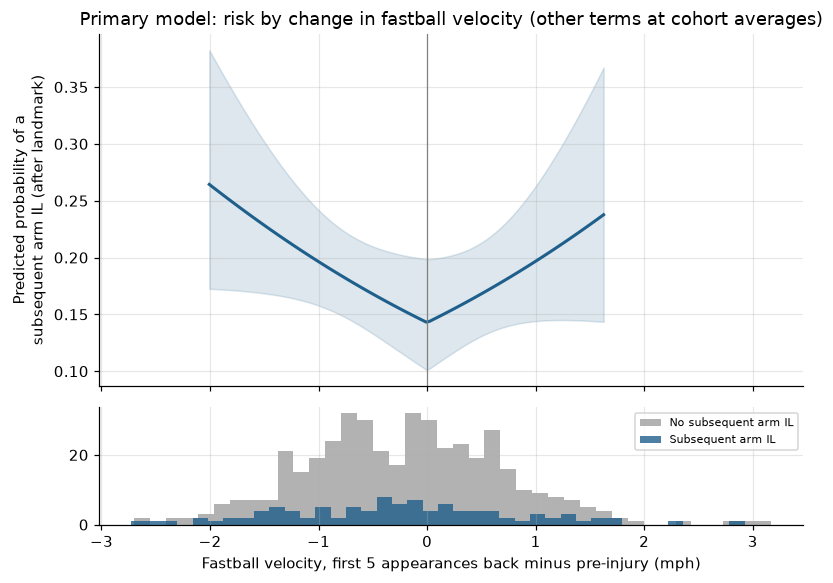

,velocity change (mph),predicted risk,lower95,upper95
0,-2.0,0.264,0.172,0.381
1,-1.5,0.228,0.168,0.302
2,-1.0,0.196,0.158,0.242
3,-0.5,0.168,0.133,0.210
4,0.0,0.143,0.101,0.198
5,0.5,0.168,0.131,0.213
6,1.0,0.197,0.144,0.263
7,1.5,0.229,0.144,0.343
8,2.0,0.265,0.140,0.443


In [14]:
tab_p, info_p, beta_p, V_p, D_p = fits["Primary (adjusted)"]
terms_p = PRIMARY_TERMS
means = D_p[terms_p].mean()


def design_at(dv):
    rows = []
    for v in np.atleast_1d(dv):
        x = means.copy()
        x["mph_lost"], x["mph_gained"] = max(-v, 0), max(v, 0)
        rows.append(np.r_[1.0, x[terms_p].to_numpy(float)])
    return np.array(rows)


grid = np.linspace(*np.nanpercentile(D_p["d_velo"], [2.5, 97.5]), 121)
Xg = design_at(grid)
eta = Xg @ beta_p
se = np.sqrt(np.einsum("ij,jk,ik->i", Xg, V_p, Xg))
expit = lambda z: 1 / (1 + np.exp(-z))
fig, (ax, axh) = plt.subplots(2, 1, figsize=(7.5, 5.4), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax.plot(grid, expit(eta), color="#1f5f8b", lw=2)
ax.fill_between(grid, expit(eta - 1.96 * se), expit(eta + 1.96 * se), color="#1f5f8b", alpha=0.15)
ax.axvline(0, color="grey", lw=0.8)
ax.set_ylabel("Predicted probability of a\nsubsequent arm IL (after landmark)")
ax.set_title("Primary model: risk by change in fastball velocity (other terms at cohort averages)")
axh.hist(D_p.loc[D_p["case"] == 0, "d_velo"], bins=40, color="grey", alpha=0.6, label="No subsequent arm IL")
axh.hist(D_p.loc[D_p["case"] == 1, "d_velo"], bins=40, color="#1f5f8b", alpha=0.8, label="Subsequent arm IL")
axh.set_xlabel(f"Fastball velocity, first {LANDMARK} appearances back minus pre-injury (mph)")
axh.legend(fontsize=7)
fig.tight_layout()
save(fig, "V2_predicted_risk_by_velocity_change")

pts = np.array([-2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2])
Xp = design_at(pts)
ep, sp = Xp @ beta_p, np.sqrt(np.einsum("ij,jk,ik->i", Xp, V_p, Xp))
risk_tab = pd.DataFrame({"velocity change (mph)": pts, "predicted risk": expit(ep),
                         "lower95": expit(ep - 1.96 * sp), "upper95": expit(ep + 1.96 * sp)})
risk_tab.to_csv(OUT_DIR / "predicted_risk_table.csv", index=False)
display(risk_tab.round(3))

## 12. Sensitivity analyses (primary model refitted)

| Variant | Change |
|---|---|
| landmark 3 | exposure over the first `LANDMARK_SENS` appearances; outcome after the 3rd |
| one season per pitcher | earliest analysed season per pitcher only |
| elbow → elbow | initial elbow/forearm injury; outcome = subsequent elbow/forearm IL |
| season-adjusted | primary model + season indicators |
| ≥ 5 pre-injury games | stricter baseline |
| no era adjustment | primary model without the IL-era terms (the v5 model) |
| pre-injury window within one tracking system | pre-injury velocity and CV from games tracked by the monitored season's system |
| no pre-injury window across a tracking change | pitcher-seasons whose window crosses a change dropped |
| 2021–2026 only | the v5 seasons (reproduces v5 apart from the era terms) |
| 2016–2019 only | the added seasons |
| starters / relievers | separate fits (exploratory; role term dropped) |
| leave one season out | primary model refitted without each season in turn (stability) |

/tmp/ipykernel_19434/131495712.py:47: RuntimeWarning: invalid value encountered in sqrt
  se = np.sqrt(np.diag(V))


,,term,"Velocity lost, per mph","Velocity gained, per mph","Within-game CV difference, per 0.1 % points"
variant,pitcher-seasons,events,,,
main,536,102,1.47 (0.99–2.17),1.47 (0.89–2.43),1.10 (0.99–1.22)
landmark 3,468,93,1.71 (1.16–2.52),1.64 (0.99–2.70),1.07 (0.95–1.21)
one season per pitcher,412,78,1.76 (1.14–2.71),1.38 (0.75–2.54),1.13 (1.00–1.28)
elbow -> elbow,239,34,1.11 (0.60–2.05),1.31 (0.61–2.78),1.16 (0.94–1.44)
season-adjusted,536,102,1.45 (0.96–2.17),1.50 (0.90–2.49),1.10 (0.99–1.23)
>= 5 pre-injury games,519,97,1.49 (1.01–2.22),1.42 (0.84–2.39),1.08 (0.96–1.21)
no era adjustment,536,102,1.45 (0.98–2.15),1.45 (0.87–2.39),1.10 (0.98–1.22)
pre-injury window within one tracking system,508,95,1.43 (0.91–2.25),1.54 (0.93–2.54),1.10 (0.98–1.23)
no pre-injury window across a tracking change,476,89,1.48 (0.94–2.33),1.52 (0.92–2.52),1.10 (0.98–1.23)


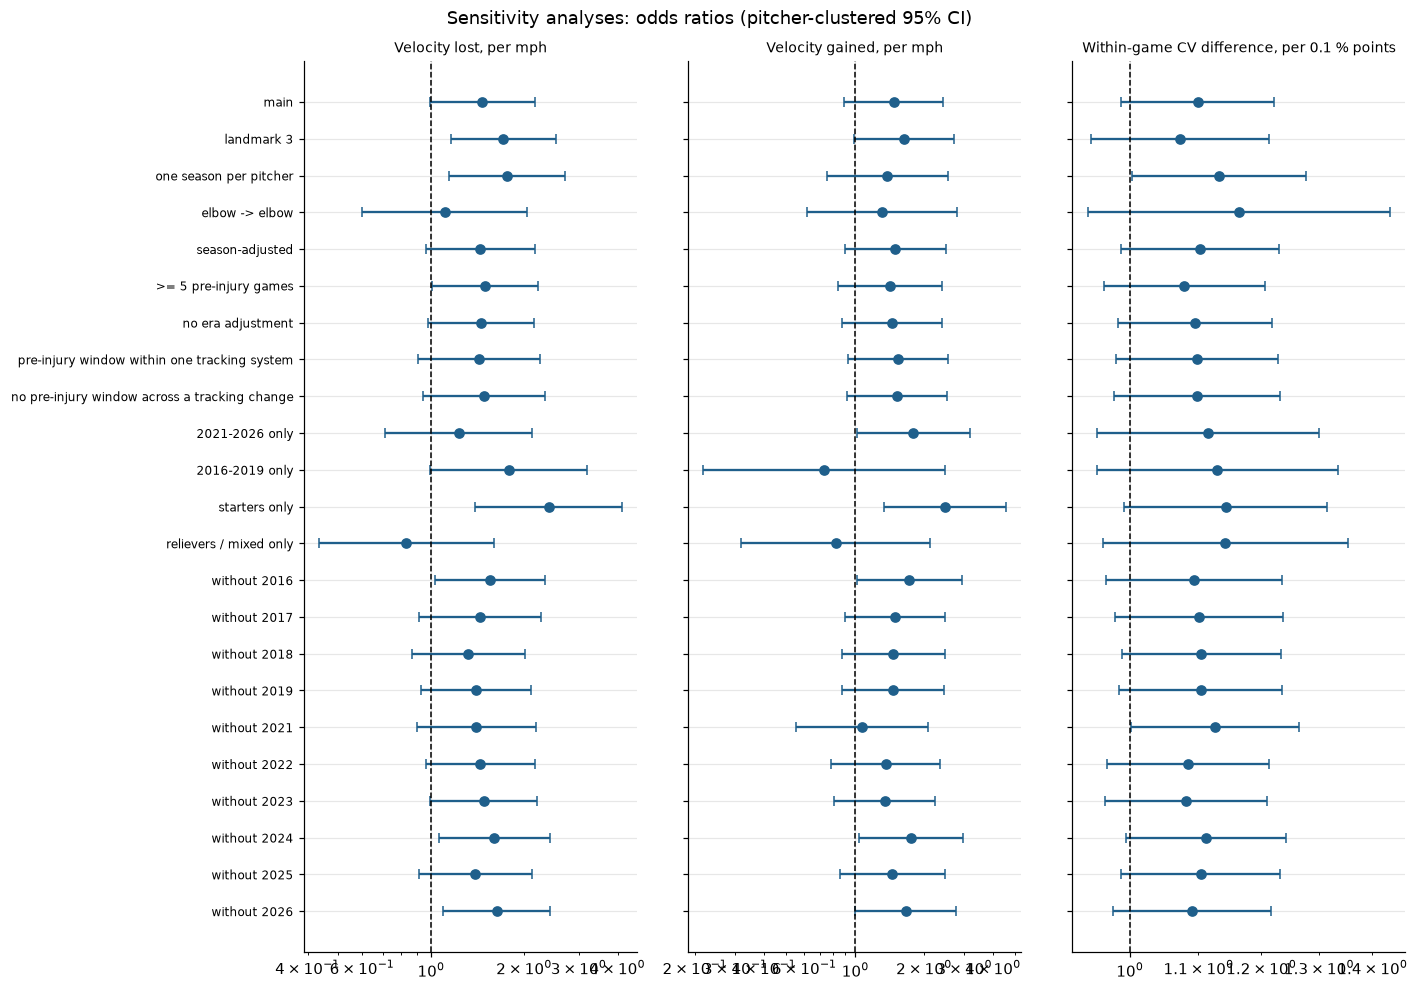

In [15]:
NO_ERA = [t for t in PRIMARY_TERMS if t not in ERA_TERMS]
key_terms = ["Velocity lost, per mph", "Velocity gained, per mph", f"Within-game CV difference, per {CV_SCALE} % points"]
sens = []


def add(label, df, terms):
    if df["case"].sum() < 5:
        print(f"{label}: fewer than 5 events, skipped")
        return
    tab, info, *_ = fit_model(df, terms, label)
    for _, r in tab.loc[tab["term"].isin(key_terms)].iterrows():
        sens.append({"variant": label, "pitcher-seasons": info["pitcher-seasons"], "events": info["events"],
                     "term": r["term"], "OR": r["OR"], "lower95": r["OR lower95"], "upper95": r["OR upper95"], "p": r["p"]})


add("main", D, PRIMARY_TERMS)
LM3 = landmark_frame(L=LANDMARK_SENS)
add(f"landmark {LANDMARK_SENS}", LM3.loc[LM3["status"] == "included"].dropna(subset=["d_velo", "d_cv"]), PRIMARY_TERMS)
first_season = D.sort_values("Season").groupby("pkey").head(1)
add("one season per pitcher", first_season, PRIMARY_TERMS)
LME = landmark_frame(outcome_group="elbow")
DE = LME.loc[(LME["status"] == "included") & (LME["elbow_initial"] == 1)].dropna(subset=["d_velo", "d_cv"])
add("elbow -> elbow", DE, [t for t in PRIMARY_TERMS if t != "elbow_initial"])
seasons_present = sorted(D["Season"].unique())
for s in seasons_present[1:]:
    D[f"season_{s}"] = (D["Season"] == s).astype(float)
add("season-adjusted", D, NO_ERA + [f"season_{s}" for s in seasons_present[1:]])   # seasons nest eras
add(">= 5 pre-injury games", D.loc[D["n_pre_games"] >= 5], PRIMARY_TERMS)
add("no era adjustment", D, NO_ERA)
LMS = landmark_frame(same_system=True)
add("pre-injury window within one tracking system",
    LMS.loc[LMS["status"] == "included"].dropna(subset=["d_velo", "d_cv"]), PRIMARY_TERMS)
add("no pre-injury window across a tracking change", D.loc[~D["baseline_crosses_system"].astype(bool)], PRIMARY_TERMS)


def era_terms_for(df):
    return NO_ERA + [t for t in ERA_TERMS if 0 < df[t].sum() < len(df)]


D21, D16 = D.loc[D["Season"] >= 2021], D.loc[D["Season"] <= 2019]
add("2021-2026 only", D21, era_terms_for(D21))
add("2016-2019 only", D16, era_terms_for(D16))
add("starters only", D.loc[D["starter"] == 1], [t for t in PRIMARY_TERMS if t != "starter"])
add("relievers / mixed only", D.loc[D["starter"] == 0], [t for t in PRIMARY_TERMS if t != "starter"])
for s in seasons_present:
    Ds = D.loc[D["Season"] != s]
    add(f"without {s}", Ds, era_terms_for(Ds))
sensitivity = pd.DataFrame(sens)
sensitivity.to_csv(OUT_DIR / "sensitivity_models.csv", index=False)
sensitivity["OR (95% CI)"] = [f"{o:.2f} ({l:.2f}–{u:.2f})" for o, l, u in
                              zip(sensitivity["OR"], sensitivity["lower95"], sensitivity["upper95"])]
display(sensitivity.pivot_table(index=["variant", "pitcher-seasons", "events"], columns="term",
                                values="OR (95% CI)", aggfunc="first", sort=False))

fig, axes = plt.subplots(1, 3, figsize=(13, 0.32 * sensitivity["variant"].nunique() + 1.8), sharey=True)
variants_order = list(dict.fromkeys(sensitivity["variant"]))
for ax, term in zip(axes, key_terms):
    s = sensitivity.loc[sensitivity["term"] == term].set_index("variant").reindex(variants_order)
    y = np.arange(len(s))[::-1]
    ax.errorbar(s["OR"], y, xerr=[s["OR"] - s["lower95"], s["upper95"] - s["OR"]], fmt="o", capsize=3, color="#1f5f8b")
    ax.axvline(1, color="black", ls="--", lw=1)
    ax.set_xscale("log")
    ax.set_title(term, fontsize=9)
    ax.set_yticks(y, variants_order, fontsize=8)
fig.suptitle("Sensitivity analyses: odds ratios (pitcher-clustered 95% CI)")
fig.tight_layout()
save(fig, "V3_sensitivity")

In [17]:
%pip install scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 35.0 MB/s  0:00:016m0:00:010:01

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [19]:
# Interaction tests: does the velocity association differ by role, or by period (2021+ vs 2016-2019)?
def wald(beta, V, idx):
    b, S = beta[idx], V[np.ix_(idx, idx)]
    stat = float(b @ np.linalg.pinv(S) @ b)
    return stat, len(idx), float(np.exp(-stat / 2) * sum((stat / 2) ** k / np.math.factorial(k) for k in range(len(idx) // 2))) \
        if len(idx) % 2 == 0 else np.nan

from scipy.stats import chi2
D["modern"] = (D["Season"] >= 2021).astype(float)
rows = []
for mod, label in [("starter", "role (starter vs reliever/mixed)"), ("modern", "period (2021-2026 vs 2016-2019)")]:
    Di = D.copy()
    Di[f"mph_lost_x_{mod}"] = Di["mph_lost"] * Di[mod]
    Di[f"mph_gained_x_{mod}"] = Di["mph_gained"] * Di[mod]
    base = PRIMARY_TERMS + ([] if mod in PRIMARY_TERMS else [mod])
    if mod == "modern":                       # period nests the era terms: use period alone
        base = NO_ERA + ["modern"]
    terms = base + [f"mph_lost_x_{mod}", f"mph_gained_x_{mod}"]
    tab, info, beta, V, _ = fit_model(Di, terms, f"interaction: {label}")
    idx = [1 + terms.index(f"mph_lost_x_{mod}"), 1 + terms.index(f"mph_gained_x_{mod}")]
    stat = float(beta[idx] @ np.linalg.pinv(V[np.ix_(idx, idx)]) @ beta[idx])
    rows.append({"modifier": label, "joint Wald chi2 (2 df)": round(stat, 2), "p": round(chi2.sf(stat, 2), 4),
                 "p (mph lost x)": round(tab.loc[tab["term"] == f"mph_lost_x_{mod}", "p"].iat[0], 4),
                 "p (mph gained x)": round(tab.loc[tab["term"] == f"mph_gained_x_{mod}", "p"].iat[0], 4)})
interactions = pd.DataFrame(rows)
interactions.to_csv(OUT_DIR / "interaction_tests.csv", index=False)
display(interactions)
print(interactions)

,modifier,joint Wald chi2 (2 df),p,p (mph lost x),p (mph gained x)
0,role (starter vs reliever/mixed),6.95,0.0310,0.0098,0.0694
1,period (2021-2026 vs 2016-2019),4.40,0.1105,0.4286,0.1665


                           modifier  joint Wald chi2 (2 df)       p  \
0  role (starter vs reliever/mixed)                    6.95  0.0310   
1   period (2021-2026 vs 2016-2019)                    4.40  0.1105   

   p (mph lost x)  p (mph gained x)  
0          0.0098            0.0694  
1          0.4286            0.1665  


In [21]:
# Role-specific odds ratios from the role-interaction model (primary terms + velocity x starter)
Di = D.copy()
Di["mph_lost_x_starter"] = Di["mph_lost"] * Di["starter"]
Di["mph_gained_x_starter"] = Di["mph_gained"] * Di["starter"]
terms = PRIMARY_TERMS + ["mph_lost_x_starter", "mph_gained_x_starter"]
tab, info, beta, V, _ = fit_model(Di, terms, "role interaction")
display(pd.DataFrame([info]))

out_rows = []
for term in ["mph_lost", "mph_gained"]:
    i, j = 1 + terms.index(term), 1 + terms.index(f"{term}_x_starter")
    for role, c in [("relievers / mixed", np.eye(len(beta))[i]),
                    ("starters", np.eye(len(beta))[i] + np.eye(len(beta))[j])]:
        b, se = c @ beta, np.sqrt(c @ V @ c)
        out_rows.append({"term": TERM_LABEL[term], "role": role, "OR": np.exp(b),
                         "lower95": np.exp(b - 1.96 * se), "upper95": np.exp(b + 1.96 * se),
                         "p": 2 * (1 - Phi(abs(b / se)))})
role_or = pd.DataFrame(out_rows)
role_or["OR (95% CI)"] = [f"{o:.2f} ({l:.2f}–{u:.2f})" for o, l, u in zip(role_or["OR"], role_or["lower95"], role_or["upper95"])]
role_or.to_csv(OUT_DIR / "role_specific_odds_ratios.csv", index=False)
n = D.groupby("starter").agg(pitcher_seasons=("uid", "size"), events=("case", "sum"))
print(n.rename(index={0.0: "relievers / mixed", 1.0: "starters"}))
display(role_or[["term", "role", "OR (95% CI)", "p"]].round(4))
print(role_or[["term", "role", "OR (95% CI)", "p"]].round(4))

,model,pitcher-seasons,events,pitchers,parameters,events per parameter,in-sample AUC,converged
0,role interaction,536,102,412,12,8.5,0.631743,True


                   pitcher_seasons  events
starter                                   
relievers / mixed              265      52
starters                       271      50


,term,role,OR (95% CI),p
0,"Velocity lost, per mph",relievers / mixed,0.81 (0.43–1.53),0.5127
1,"Velocity lost, per mph",starters,2.42 (1.42–4.12),0.0012
2,"Velocity gained, per mph",relievers / mixed,0.74 (0.28–1.94),0.5387
3,"Velocity gained, per mph",starters,2.12 (1.17–3.85),0.0130


                       term               role       OR (95% CI)       p
0    Velocity lost, per mph  relievers / mixed  0.81 (0.43–1.53)  0.5127
1    Velocity lost, per mph           starters  2.42 (1.42–4.12)  0.0012
2  Velocity gained, per mph  relievers / mixed  0.74 (0.28–1.94)  0.5387
3  Velocity gained, per mph           starters  2.12 (1.17–3.85)  0.0130


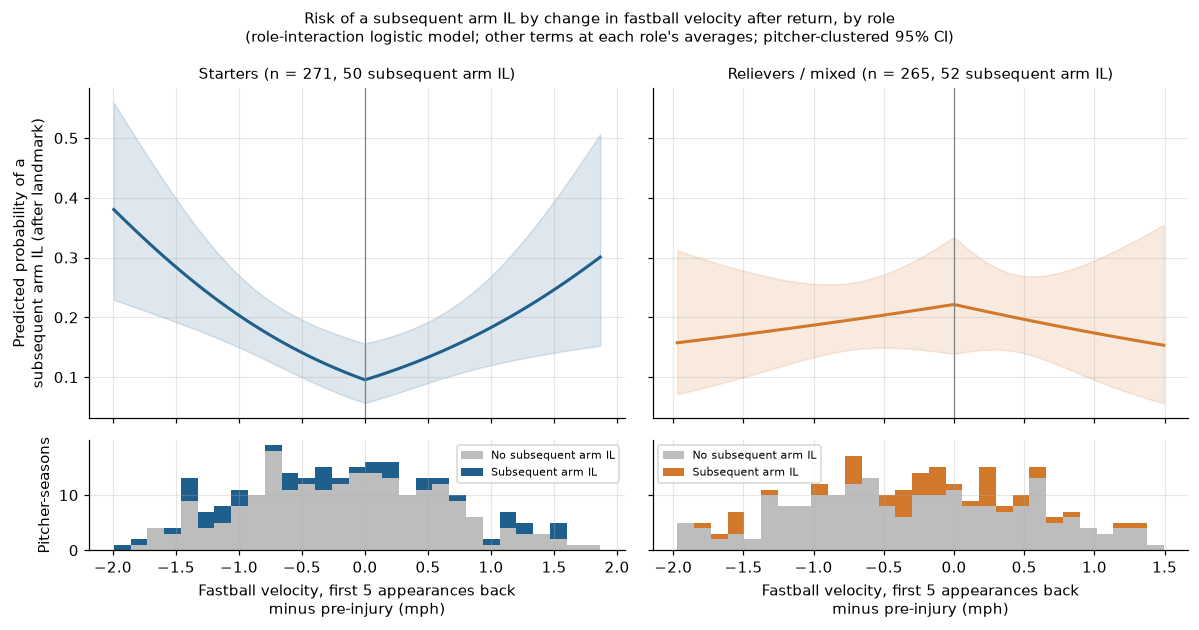

role,Relievers / mixed,Starters
velocity change (mph),,
-2.0,0.157,0.382
-1.5,0.171,0.284
-1.0,0.187,0.203
-0.5,0.204,0.141
0.0,0.222,0.095
0.5,0.197,0.133
1.0,0.174,0.183
1.5,0.153,0.246
2.0,0.135,0.322


Full table with 95% CIs: predicted_risk_by_role.csv


In [22]:
# ==== Predicted risk by velocity change, starters vs relievers/mixed (role-interaction model) ====
# Paste at the end of Section 12. Refits the role-interaction model (primary terms + velocity x starter), so it
# runs on its own. All other terms (CV difference, age, initial elbow/forearm, days on IL, IL era) are held at
# the averages of that role's own pitcher-seasons, so each curve describes a typical pitcher of that role.

expit = lambda z: 1 / (1 + np.exp(-z))
Dr = D.copy()
Dr["mph_lost_x_starter"] = Dr["mph_lost"] * Dr["starter"]
Dr["mph_gained_x_starter"] = Dr["mph_gained"] * Dr["starter"]
terms_r = PRIMARY_TERMS + ["mph_lost_x_starter", "mph_gained_x_starter"]
tab_r, info_r, beta_r, V_r, D_r = fit_model(Dr, terms_r, "role interaction")

ROLE_GROUPS = [(1.0, "Starters", "#1f5f8b"), (0.0, "Relievers / mixed", "#d1782a")]


def design_role(dv, starter):
    x = D_r.loc[D_r["starter"] == starter, terms_r].mean()
    rows = []
    for v in np.atleast_1d(dv):
        x = x.copy()
        x["starter"] = starter
        x["mph_lost"], x["mph_gained"] = max(-v, 0), max(v, 0)
        x["mph_lost_x_starter"], x["mph_gained_x_starter"] = x["mph_lost"] * starter, x["mph_gained"] * starter
        rows.append(np.r_[1.0, x[terms_r].to_numpy(float)])
    return np.array(rows)


fig, axes = plt.subplots(2, 2, figsize=(11, 5.8), sharex="col", sharey="row",
                         gridspec_kw={"height_ratios": [3, 1]})
risk_rows = []
pts = np.array([-2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2])
for col, (st, name, color) in enumerate(ROLE_GROUPS):
    sub = D_r.loc[D_r["starter"] == st]
    grid = np.linspace(*np.nanpercentile(sub["d_velo"], [2.5, 97.5]), 121)
    Xg = design_role(grid, st)
    eta, se = Xg @ beta_r, np.sqrt(np.einsum("ij,jk,ik->i", Xg, V_r, Xg))
    ax = axes[0, col]
    ax.plot(grid, expit(eta), color=color, lw=2)
    ax.fill_between(grid, expit(eta - 1.96 * se), expit(eta + 1.96 * se), color=color, alpha=0.15)
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_title(f"{name} (n = {len(sub)}, {int(sub['case'].sum())} subsequent arm IL)", fontsize=10)
    if col == 0:
        ax.set_ylabel("Predicted probability of a\nsubsequent arm IL (after landmark)")
    axh = axes[1, col]
    bins = np.linspace(grid.min(), grid.max(), 30)
    axh.hist([sub.loc[sub["case"] == 0, "d_velo"], sub.loc[sub["case"] == 1, "d_velo"]], bins=bins, stacked=True,
             color=["#bdbdbd", color], label=["No subsequent arm IL", "Subsequent arm IL"])
    axh.set_xlabel(f"Fastball velocity, first {LANDMARK} appearances back\nminus pre-injury (mph)")
    axh.legend(fontsize=7)
    Xp = design_role(pts, st)
    ep, sp = Xp @ beta_r, np.sqrt(np.einsum("ij,jk,ik->i", Xp, V_r, Xp))
    risk_rows += [{"role": name, "velocity change (mph)": p, "predicted risk": r, "lower95": l, "upper95": u}
                  for p, r, l, u in zip(pts, expit(ep), expit(ep - 1.96 * sp), expit(ep + 1.96 * sp))]
axes[1, 0].set_ylabel("Pitcher-seasons")
fig.suptitle("Risk of a subsequent arm IL by change in fastball velocity after return, by role\n"
             "(role-interaction logistic model; other terms at each role's averages; pitcher-clustered 95% CI)",
             fontsize=10)
fig.tight_layout()
save(fig, "V2b_predicted_risk_by_velocity_change_by_role")

role_risk = pd.DataFrame(risk_rows)
role_risk.to_csv(OUT_DIR / "predicted_risk_by_role.csv", index=False)
display(role_risk.pivot(index="velocity change (mph)", columns="role", values="predicted risk").round(3))
print("Full table with 95% CIs: predicted_risk_by_role.csv")

## 13. Notes for interpretation

* **Association, not prediction or cause.** A drop in velocity may be an early sign of an injury already
  developing; the landmark design ensures only that it is measured before the IL placement.
* **Reinjuries within the first `LANDMARK` appearances** are outside the model by design (Section 7 counts
  them). If they are a large share of all reinjuries, the landmark-3 sensitivity analysis matters more.
* **Two directions.** "Velocity gained" tests the load hypothesis; read its odds ratio next to "velocity lost".
* **Multiple seasons per pitcher.** Intervals are pitcher-clustered; the one-season-per-pitcher row checks it.
* **Events per parameter.** With about 10 or fewer, intervals are approximate; the unadjusted model is the check.
* **2016–2019 rows** come from MLB transactions: IL dates can differ by a few days from FanGraphs, and
  rows with no injury text count as non-arm (Section 2 counts them).
* **Eras and tracking systems.** Read the primary result next to the "no era adjustment", "within one
  tracking system" and 2016–2019 vs 2021–2026 rows of Section 12.
* **Not adjusted for** ballpark or temperature (needs `home_team` from Statcast).